In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_excel(r'/content/food analysis.xlsx')

In [ ]:
df.info()
print('Shape of data:', df.shape)
print('Columns of data:', df.columns)
print('NULL VALUES:', df.isnull().sum())
print('DUplicated values:', df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB
Shape of data: (1898, 9)
Columns of data: Index(['order_id', 'customer_id', 'restaurant_name', 'cuisine_type',
       'cost_of_the_order', 'day_of_the_week', 'rating',
       'food_preparation_time', 'delivery_time'],
      dtype='object')
NULL VALUES: order

In [ ]:

df.describe()


,order_id,customer_id,cost_of_the_order,food_preparation_time,delivery_time
count,1.898000e+03,1898.000000,1898.000000,1898.000000,1898.000000
mean,1.477496e+06,171168.478398,16.498851,27.371970,24.161749
std,5.480497e+02,113698.139743,7.483812,4.632481,4.972637
min,1.476547e+06,1311.000000,4.470000,20.000000,15.000000
25%,1.477021e+06,77787.750000,12.080000,23.000000,20.000000
50%,1.477496e+06,128600.000000,14.140000,27.000000,25.000000
75%,1.477970e+06,270525.000000,22.297500,31.000000,28.000000
max,1.478444e+06,405334.000000,35.410000,35.000000,33.000000


In [ ]:
df['rating'] = df['rating'].replace('Not given', np.nan)
df['rating']=pd.to_numeric(df['rating'],errors='coerce')
df['rating'].value_counts(dropna=False)
print('MEAN_OF_RATING:',df['rating'].mean())

MEAN_OF_RATING: 4.344234079173838


Most popular cuisines


In [ ]:
df['cuisine_type'].value_counts(dropna=False)

,count
cuisine_type,
American,584
Japanese,470
Italian,298
Chinese,215
Mexican,77
Indian,73
Middle Eastern,49
Mediterranean,46
Thai,19


In [ ]:
(df['cuisine_type'].value_counts(normalize=True)*100).round(2)

,proportion
cuisine_type,
American,30.77
Japanese,24.76
Italian,15.70
Chinese,11.33
Mexican,4.06
Indian,3.85
Middle Eastern,2.58
Mediterranean,2.42
Thai,1.00


Orders on weekdays versus weekends


In [ ]:
df['day_of_the_week'].value_counts(dropna=False)
(df['day_of_the_week'].value_counts(normalize=True)*100).round(2)

,proportion
day_of_the_week,
Weekend,71.18
Weekday,28.82


Top 10 restaurants

In [ ]:
df['restaurant_name'].value_counts(dropna=False).head(10)

,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68
RedFarm Broadway,59
RedFarm Hudson,55
TAO,49
Han Dynasty,46


In [ ]:
# Select numerical columns and then drop 'order_id' and 'customer_id' columns
numerical = df.select_dtypes(exclude='object').drop(columns=['order_id', 'customer_id'], errors='ignore')
categorical = df.select_dtypes(include='object')

print('Numerical columns:', numerical.columns.tolist())
print('Categorical columns:', categorical.columns.tolist())

Numerical columns: ['cost_of_the_order', 'rating', 'food_preparation_time', 'delivery_time']
Categorical columns: ['restaurant_name', 'cuisine_type', 'day_of_the_week']


In [ ]:
numerical.agg(['mean', 'median', 'std'])

,cost_of_the_order,rating,food_preparation_time,delivery_time
mean,16.498851,4.344234,27.371970,24.161749
median,14.140000,5.000000,27.000000,25.000000
std,7.483812,0.741478,4.632481,4.972637


In [43]:
for col in categorical:
    print(f"\nColumn: {col}")
    print(categorical[col].value_counts().head(10))



Column: restaurant_name
restaurant_name
Shake Shack                      219
The Meatball Shop                132
Blue Ribbon Sushi                119
Blue Ribbon Fried Chicken         96
Parm                              68
RedFarm Broadway                  59
RedFarm Hudson                    55
TAO                               49
Han Dynasty                       46
Blue Ribbon Sushi Bar & Grill     44
Name: count, dtype: int64

Column: cuisine_type
cuisine_type
American          584
Japanese          470
Italian           298
Chinese           215
Mexican            77
Indian             73
Middle Eastern     49
Mediterranean      46
Thai               19
French             18
Name: count, dtype: int64

Column: day_of_the_week
day_of_the_week
Weekend    1351
Weekday     547
Name: count, dtype: int64


Outlier Analysis


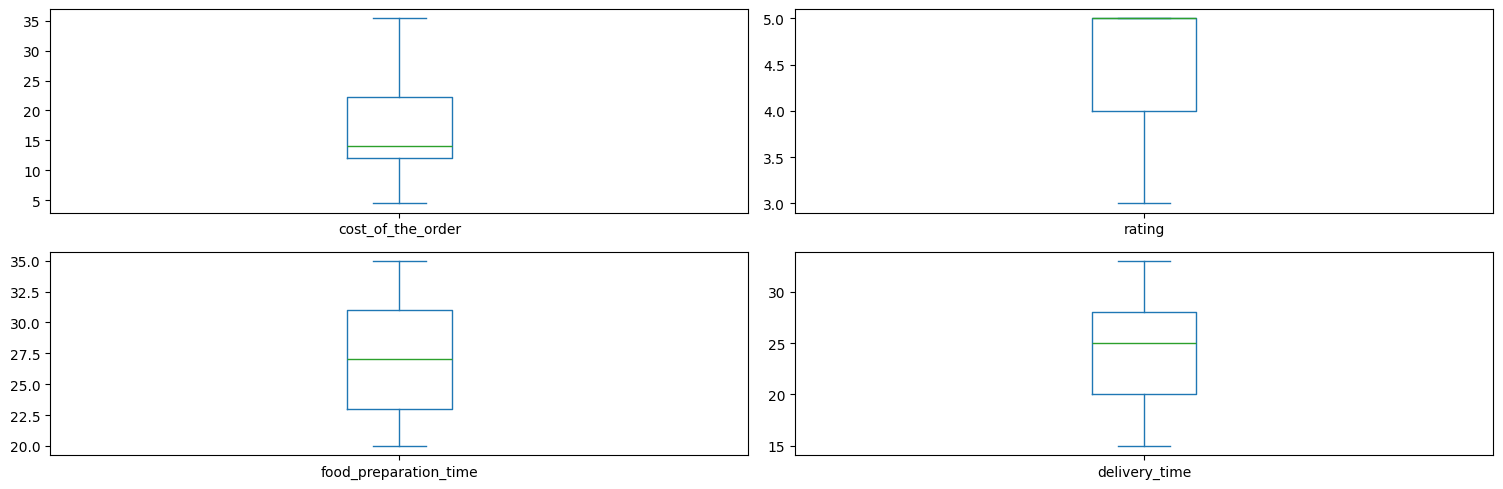

In [48]:
numerical.plot(kind='box',
               subplots=True,
               layout=(2,2),
               figsize=(15,5))
plt.tight_layout()
plt.show()

In [49]:
for col in numerical.columns:
    Q1 = numerical[col].quantile(0.25)
    Q3 = numerical[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = numerical[
        (numerical[col] < lower) |
        (numerical[col] > upper)
    ][col]

    print(f"\nColumn: {col}")
    print("Lower bound:", round(lower, 2))
    print("Upper bound:", round(upper, 2))
    print("Outlier count:", len(outliers))


Column: cost_of_the_order
Lower bound: -3.25
Upper bound: 37.62
Outlier count: 0

Column: rating
Lower bound: 2.5
Upper bound: 6.5
Outlier count: 0

Column: food_preparation_time
Lower bound: 11.0
Upper bound: 43.0
Outlier count: 0

Column: delivery_time
Lower bound: 8.0
Upper bound: 40.0
Outlier count: 0


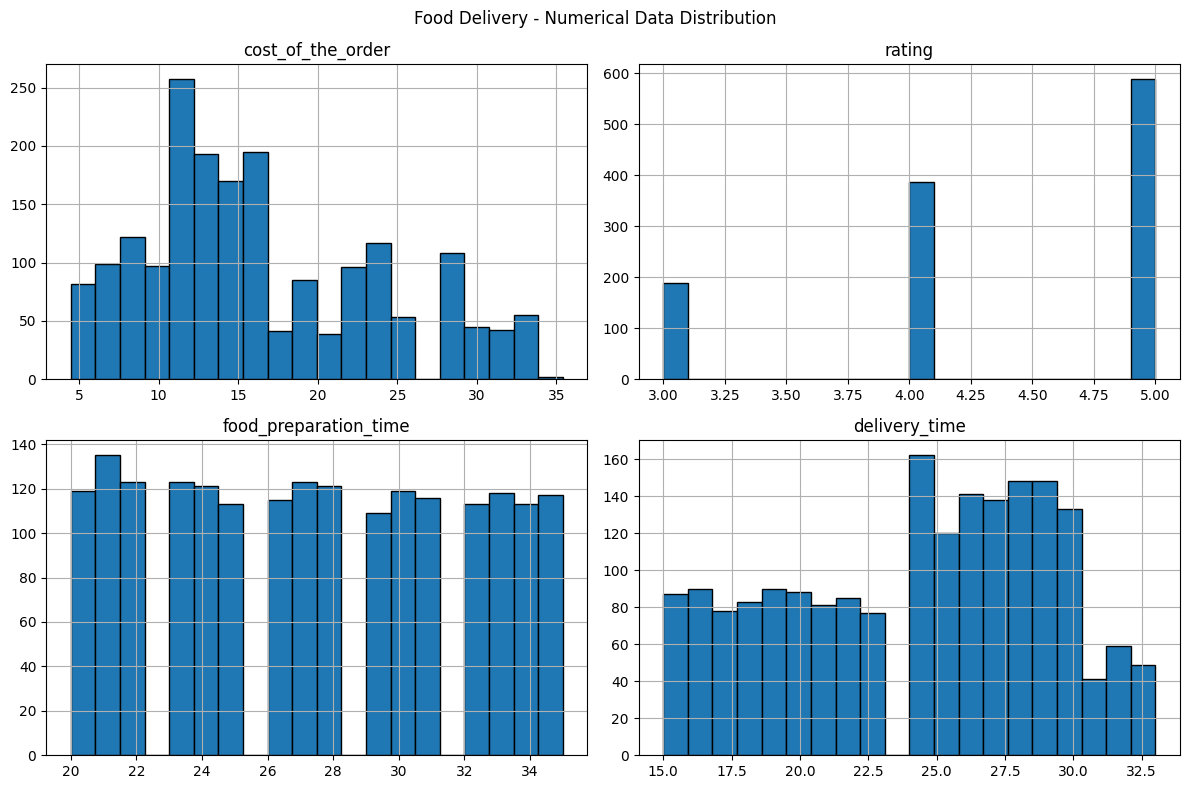

In [50]:
import matplotlib.pyplot as plt

numerical.hist(
    figsize=(12, 8),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Food Delivery - Numerical Data Distribution')
plt.tight_layout()
plt.show()

In [52]:
correlation = df['food_preparation_time'].corr(
    df['delivery_time']
)

print("Correlation:", round(correlation, 3))

Correlation: 0.011


Which cuisines generate higher order values?


In [58]:
avg_cost=df.groupby('cuisine_type')['cost_of_the_order'].mean()
avg_cost=avg_cost.sort_values(ascending=False)
print(avg_cost.round(2))

cuisine_type
French            19.79
Southern          19.30
Thai              19.21
Spanish           18.99
Middle Eastern    18.82
Mexican           16.93
Indian            16.92
Italian           16.42
American          16.32
Chinese           16.31
Japanese          16.30
Mediterranean     15.47
Korean            14.00
Vietnamese        12.88
Name: cost_of_the_order, dtype: float64


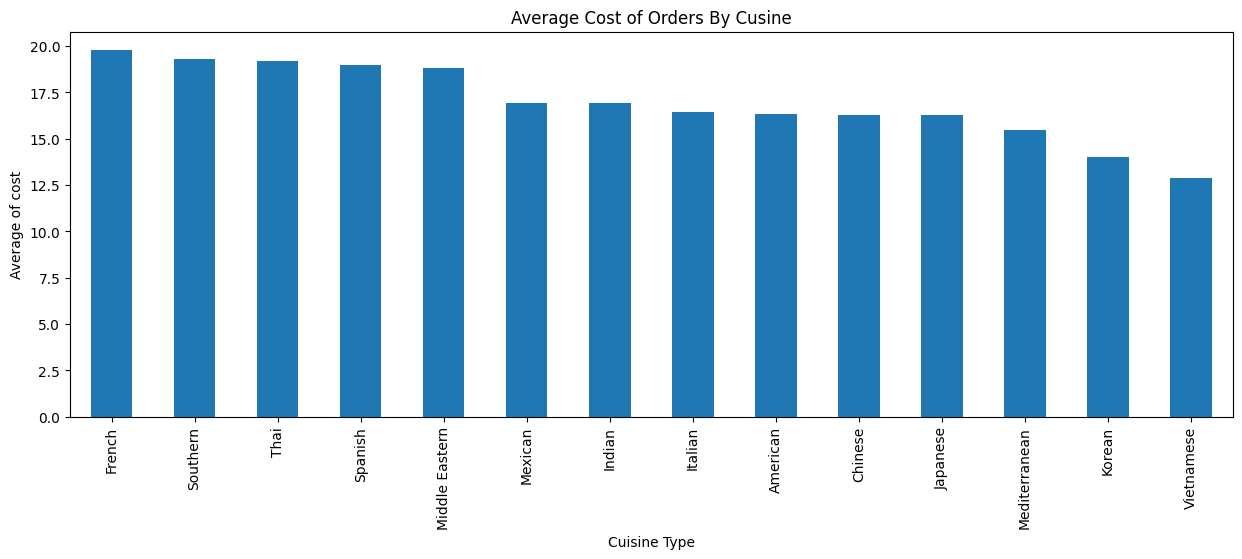

In [60]:
avg_cost.plot(kind='bar',figsize=(15,5))
plt.title('Average Cost of Orders By Cusine')
plt.xlabel('Cuisine Type')
plt.ylabel('Average of cost')
plt.show()

Compare order counts

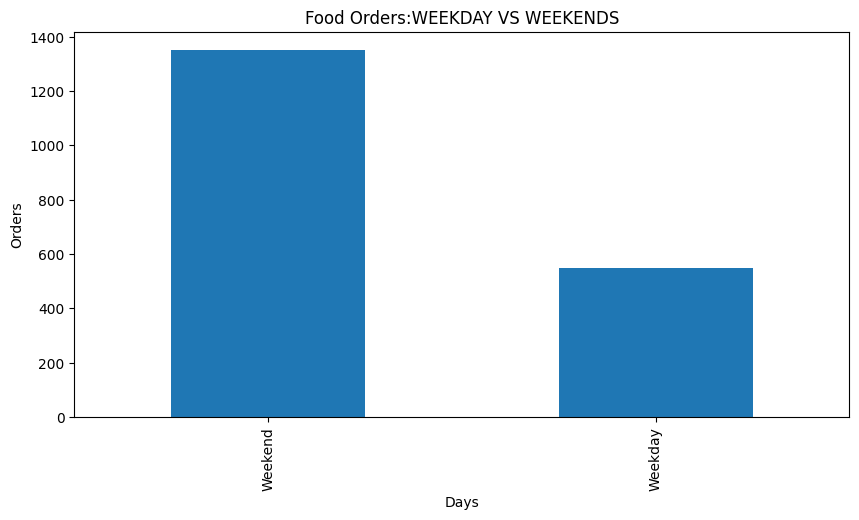

In [63]:
day_orders=df['day_of_the_week'].value_counts()
day_orders.plot(kind='bar',figsize=(10,5))
plt.title('Food Orders:WEEKDAY VS WEEKENDS')
plt.xlabel('Days')
plt.ylabel('Orders')
plt.show()

Business insight
- More weekend orders: Consider increasing staffing and delivery capacity on weekends.
- More weekday orders: Focus promotions around busy weekday meal periods.
- Similar order counts: Maintain balanced staffing and investigate peak hours for further optimization.


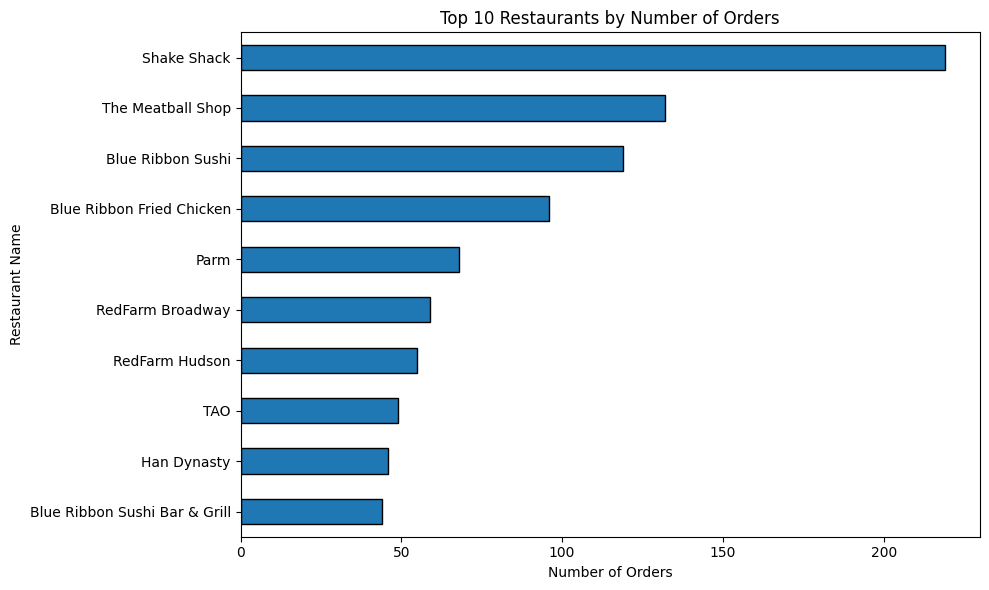

In [66]:
import matplotlib.pyplot as plt

df['restaurant_name'].value_counts().head(10).sort_values(ascending=True).plot(
    kind='barh',
    figsize=(10, 6),
    edgecolor='black'
)

plt.title('Top 10 Restaurants by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Restaurant Name')
plt.tight_layout()
plt.show()

In [67]:
customer_orders = df['customer_id'].value_counts()

print("Total unique customers:", df['customer_id'].nunique())
print("\nTop 10 customers by order count:")
print(customer_orders.head(10))

Total unique customers: 1200

Top 10 customers by order count:
customer_id
52832     13
47440     10
83287      9
250494     8
259341     7
65009      7
276192     7
82041      7
115213     6
60052      6
Name: count, dtype: int64


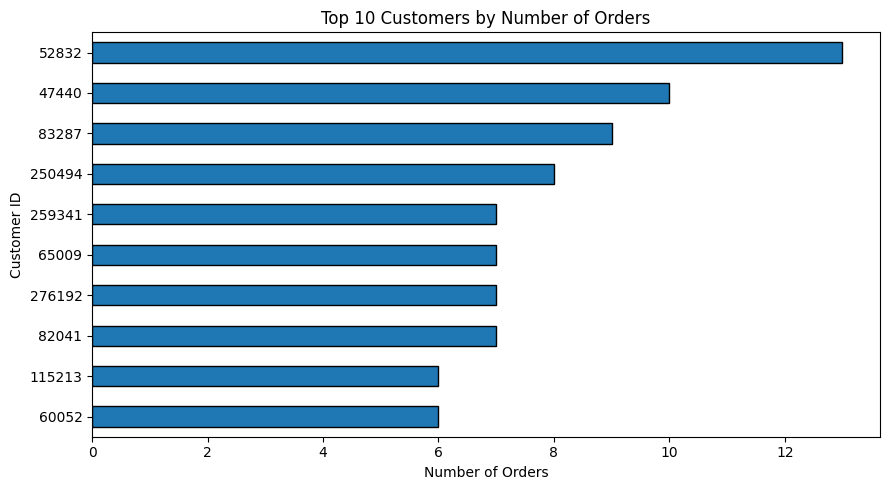

In [68]:
import matplotlib.pyplot as plt

top_customers = customer_orders.head(10).sort_values()

top_customers.plot(
    kind='barh',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('Top 10 Customers by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Customer ID')
plt.tight_layout()
plt.show()

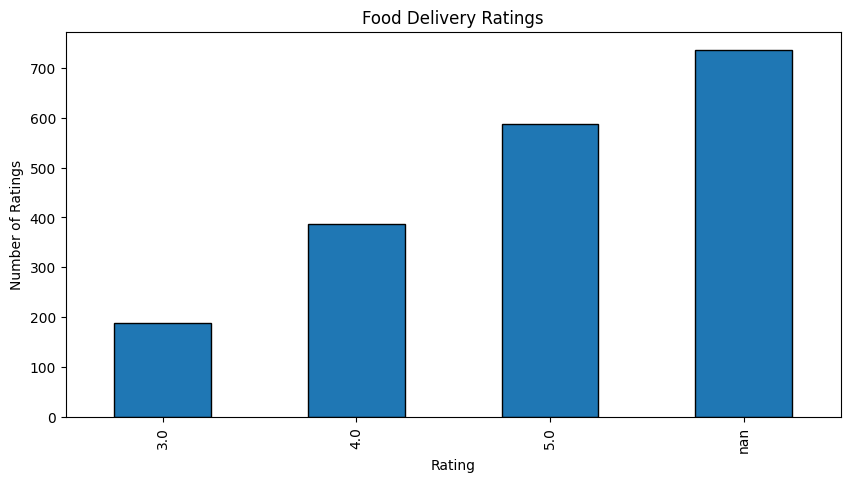

In [70]:
rating=df['rating'].value_counts(dropna=False).sort_index()
rating.plot(kind='bar',figsize=(10,5),edgecolor='black')
plt.title('Food Delivery Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Ratings')
plt.show()

In [71]:
print("Average preparation time:",
      df['food_preparation_time'].mean().round(2), "minutes")

print("Median preparation time:",
      df['food_preparation_time'].median(), "minutes")

print("Minimum preparation time:",
      df['food_preparation_time'].min(), "minutes")

print("Maximum preparation time:",
      df['food_preparation_time'].max(), "minutes")

Average preparation time: 27.37 minutes
Median preparation time: 27.0 minutes
Minimum preparation time: 20 minutes
Maximum preparation time: 35 minutes


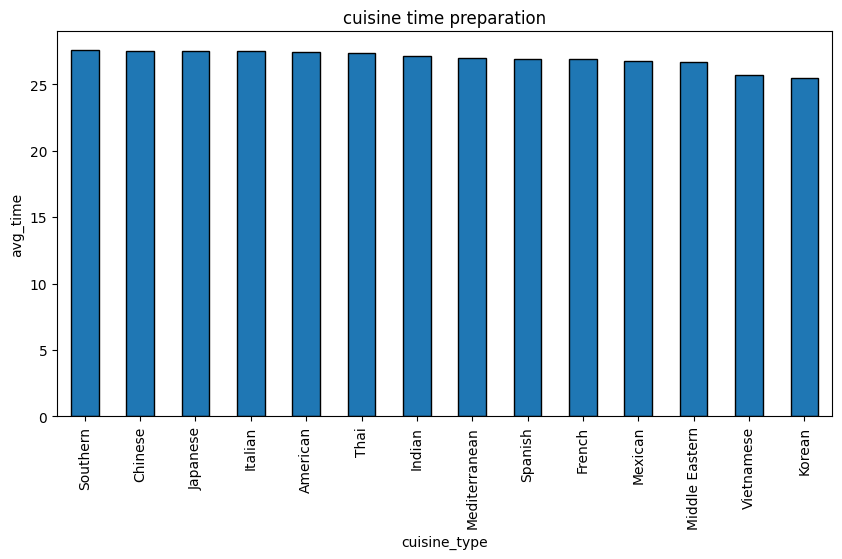

In [73]:
pre_by_cusinie=df.groupby('cuisine_type')['food_preparation_time'].mean().sort_values(ascending=False)
pre_by_cusinie.plot(kind='bar',figsize=(10,5),edgecolor='black')
plt.title('cuisine time preparation')
plt.xlabel('cuisine_type')
plt.ylabel('avg_time')
plt.show()

In [74]:
print("Average delivery time:",
      df['delivery_time'].mean().round(2), "minutes")

print("Median delivery time:",
      df['delivery_time'].median(), "minutes")

print("Minimum delivery time:",
      df['delivery_time'].min(), "minutes")

print("Maximum delivery time:",
      df['delivery_time'].max(), "minutes")

Average delivery time: 24.16 minutes
Median delivery time: 25.0 minutes
Minimum delivery time: 15 minutes
Maximum delivery time: 33 minutes


In [75]:
delivery_by_day = df.groupby('day_of_the_week')[
    'delivery_time'
].agg(['mean', 'median', 'count'])

print(delivery_by_day.round(2))

                  mean  median  count
day_of_the_week                      
Weekday          28.34    28.0    547
Weekend          22.47    22.0   1351


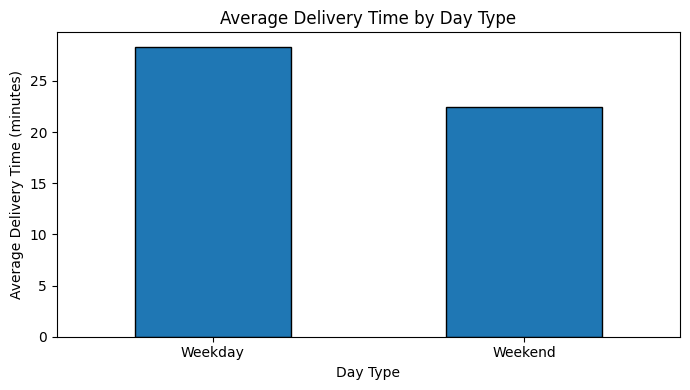

In [76]:
import matplotlib.pyplot as plt

delivery_by_day['mean'].plot(
    kind='bar',
    figsize=(7, 4),
    edgecolor='black'
)

plt.title('Average Delivery Time by Day Type')
plt.xlabel('Day Type')
plt.ylabel('Average Delivery Time (minutes)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

rating
3.0    16.22
4.0    16.71
5.0    16.97
Name: cost_of_the_order, dtype: float64


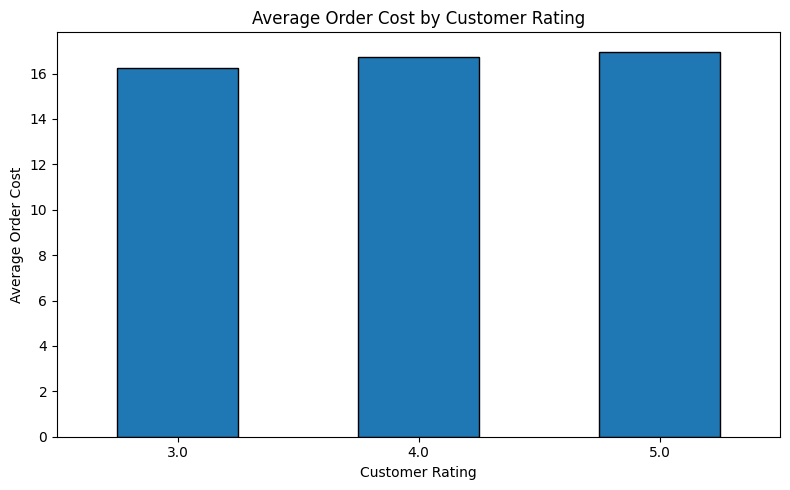

In [77]:
cost_by_rating = df.groupby('rating')['cost_of_the_order'].mean()

print(cost_by_rating.round(2))
import matplotlib.pyplot as plt

cost_by_rating.plot(
    kind='bar',
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('Average Order Cost by Customer Rating')
plt.xlabel('Customer Rating')
plt.ylabel('Average Order Cost')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [78]:
cuisine_analysis = df.groupby('cuisine_type').agg(
    total_orders=('order_id', 'count'),
    average_rating=('rating', 'mean'),
    average_cost=('cost_of_the_order', 'mean')
)

cuisine_analysis = cuisine_analysis.sort_values(
    'total_orders', ascending=False
)

print(cuisine_analysis.round(2))

                total_orders  average_rating  average_cost
cuisine_type                                              
American                 584            4.30         16.32
Japanese                 470            4.37         16.30
Italian                  298            4.36         16.42
Chinese                  215            4.34         16.31
Mexican                   77            4.42         16.93
Indian                    73            4.54         16.92
Middle Eastern            49            4.24         18.82
Mediterranean             46            4.22         15.47
Thai                      19            4.67         19.21
French                    18            4.30         19.79
Southern                  17            4.31         19.30
Korean                    13            4.11         14.00
Spanish                   12            4.83         18.99
Vietnamese                 7            4.00         12.88


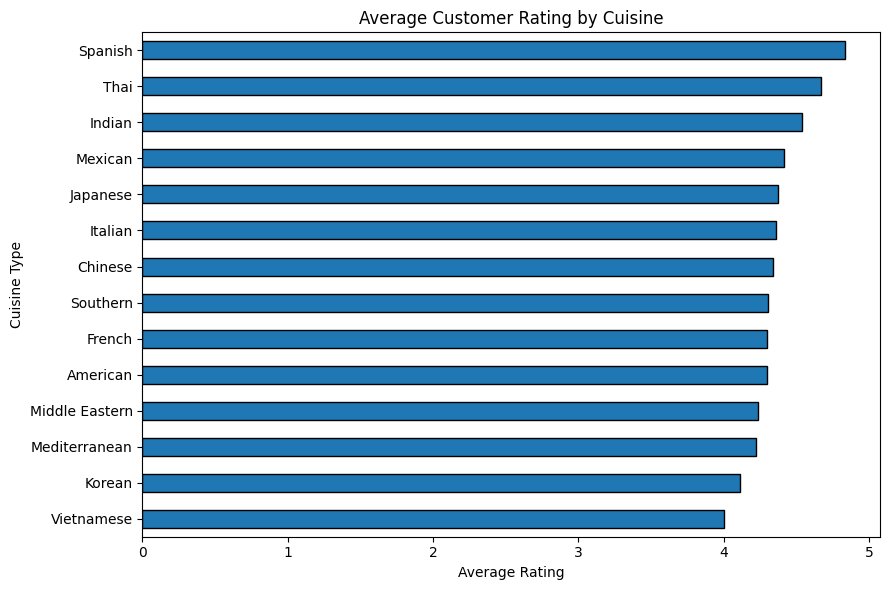

In [79]:
import matplotlib.pyplot as plt

cuisine_analysis['average_rating'].sort_values().plot(
    kind='barh',
    figsize=(9, 6),
    edgecolor='black'
)

plt.title('Average Customer Rating by Cuisine')
plt.xlabel('Average Rating')
plt.ylabel('Cuisine Type')
plt.tight_layout()
plt.show()

cuisine_type
American          9530.78
Japanese          7663.13
Italian           4892.77
Chinese           3505.62
Mexican           1303.85
Indian            1235.14
Middle Eastern     922.21
Mediterranean      711.84
Thai               364.95
French             356.29
Southern           328.11
Spanish            227.93
Korean             182.02
Vietnamese          90.18
Name: cost_of_the_order, dtype: float64


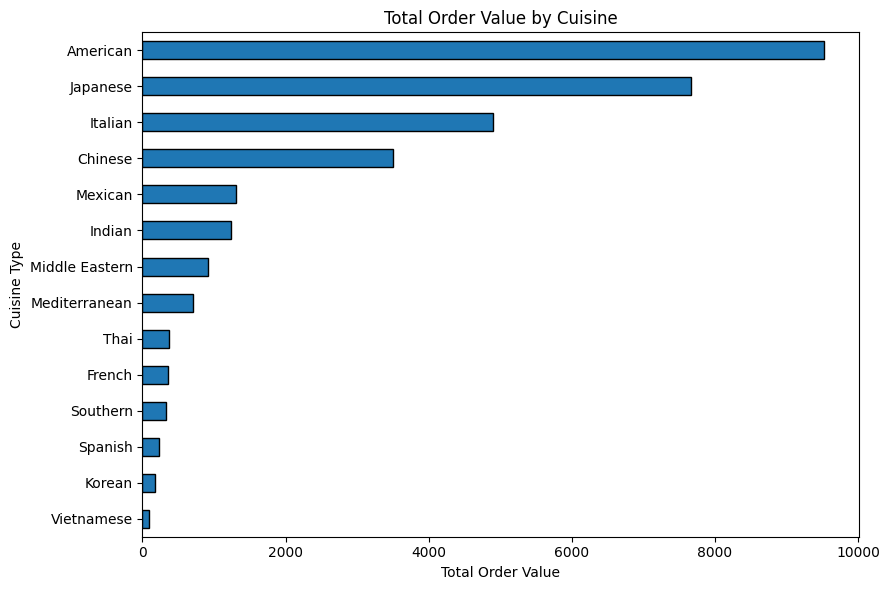

In [81]:
revenue_by_cuisine = df.groupby('cuisine_type')[
    'cost_of_the_order'
].sum().sort_values(ascending=False)

print(revenue_by_cuisine.round(2))
import matplotlib.pyplot as plt

revenue_by_cuisine.sort_values().plot(
    kind='barh',
    figsize=(9, 6),
    edgecolor='black'
)

plt.title('Total Order Value by Cuisine')
plt.xlabel('Total Order Value')
plt.ylabel('Cuisine Type')
plt.tight_layout()
plt.show()

In [82]:
eda_summary = {
    'Total Orders': len(df),
    'Unique Customers': df['customer_id'].nunique(),
    'Unique Restaurants': df['restaurant_name'].nunique(),
    'Average Order Cost': round(df['cost_of_the_order'].mean(), 2),
    'Average Food Preparation Time': round(
        df['food_preparation_time'].mean(), 2
    ),
    'Average Delivery Time': round(df['delivery_time'].mean(), 2),
    'Average Customer Rating': round(df['rating'].mean(), 2),
    'Total Order Value': round(df['cost_of_the_order'].sum(), 2)
}

import pandas as pd

summary_df = pd.DataFrame(
    eda_summary.items(),
    columns=['Metric', 'Value']
)

print(summary_df)

                          Metric     Value
0                   Total Orders   1898.00
1               Unique Customers   1200.00
2             Unique Restaurants    178.00
3             Average Order Cost     16.50
4  Average Food Preparation Time     27.37
5          Average Delivery Time     24.16
6        Average Customer Rating      4.34
7              Total Order Value  31314.82
